# Fig. 4c-f: Neural value of single sessions

[AI generated summary] In each session, the population activity is projected to the DVS of a feedback decoder, and the neural value is measured during task engagement (between lever touch and feedback):
- **Fig. 4c**: neural value as a function of the last three outcomes (Spearman correlation per session, Wilcoxon test).
- **Fig. 4d**: contribution of the last 8 outcomes to the neural value (CPD, permutation test, FDR-corrected).
- **Fig. 4e**: trial-to-trial change of the neural value after rewarded vs. unrewarded trials (Wilcoxon test).
- **Fig. 4f**: neural value in trial t+1 vs. trial t in an example MCC session.
- The number of sessions with a delta-rule consistent update of the neural value (reported in the text).

The statistics reported in the paper are printed below the figures. **How to run:** set `DATA_PATH` in `popy/config.py` (uses `behavior/recordings_summary.csv`), then run all cells. The CPD permutation test takes a few minutes. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/population_decoding/behav_neural_value` (see the README). To recompute them, run in this folder: `python run_neural_value_all_sessions.py` (several hours on a server).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
from helpers_analysis import *
from helpers import prepare_short_history_data
from popy.config import COLORS, RESULTS_PATH

plt.rcParams.update({'font.size': 8})

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

---
# Load data

In [3]:
behav_new = pd.read_pickle(os.path.join(RESULTS_PATH, 'population_decoding', 'behav_neural_value', 'behav.pkl'))
#behav_new = behav_new.loc[behav_new.subregion=='dLPFC']
# remove 5% outliers from dV
#behav_new = behav_new.loc[behav_new['V_t'].abs() < behav_new['V_t'].abs().quantile(0.95)]
behav_new = behav_new.dropna()

In [4]:
#count nans
behav_new

,monkey,session,subregion,trial_id,block_id,best_target,target,feedback,switch,stay_value,...,target_1,V_t_-4_-2,V_t_p1_-4_-2,dV_-4_-2,V_t_behav,V_t_p1_behav,dV_behav,V_t_1.5_3.5,V_t_p1_1.5_3.5,dV_1.5_3.5
0,ka,230720,MCC,8,0,2,3.0,0.0,1.0,0.283056,...,False,-0.150551,0.204889,0.355440,0.283056,0.069825,-0.213231,-0.117508,-0.109746,0.007762
1,ka,230720,MCC,9,0,2,2.0,0.0,1.0,0.069825,...,False,0.204889,-0.059881,-0.264770,0.069825,0.069825,0.000000,-0.109746,-0.055993,0.053753
2,ka,230720,MCC,10,0,2,3.0,1.0,1.0,0.069825,...,False,-0.059881,-0.200961,-0.141080,0.069825,0.479459,0.409634,-0.055993,0.064920,0.120912
3,ka,230720,MCC,11,0,2,3.0,0.0,0.0,0.479459,...,False,-0.200961,-0.070287,0.130675,0.479459,0.283056,-0.196402,0.064920,-0.083296,-0.148216
4,ka,230720,MCC,12,0,2,3.0,0.0,0.0,0.283056,...,False,-0.070287,-0.073770,-0.003484,0.283056,0.167107,-0.115949,-0.083296,0.035119,0.118415
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66350,po,200722,dLPFC,372,8,1,1.0,0.0,0.0,0.723918,...,True,0.796248,0.689507,-0.106742,0.723918,0.503993,-0.219925,0.706391,-0.005228,-0.711619
66351,po,200722,dLPFC,373,8,1,1.0,1.0,0.0,0.503993,...,True,0.689507,0.057016,-0.632490,0.503993,0.654679,0.150686,-0.005228,0.390832,0.396059
66352,po,200722,dLPFC,374,8,1,1.0,1.0,0.0,0.654679,...,True,0.057016,0.362536,0.305519,0.654679,0.759587,0.104908,0.390832,0.261081,-0.129750
66353,po,200722,dLPFC,375,8,1,1.0,1.0,0.0,0.759587,...,True,0.362536,0.786138,0.423602,0.759587,0.832624,0.073037,0.261081,0.440961,0.179879


In [5]:
# print number of sessions/subregions per monkey-subregion paris
for monkey in behav_new['monkey'].unique():
    for subregion in behav_new['subregion'].unique():
        n_sess = behav_new.loc[(behav_new['monkey']==monkey) & (behav_new['subregion']==subregion), 'session'].nunique()
        print(f"{monkey}-{subregion}: {n_sess} sessions")

ka-MCC: 58 sessions
ka-dLPFC: 46 sessions
ka-vLPFC: 12 sessions
po-MCC: 51 sessions
po-dLPFC: 40 sessions
po-vLPFC: 7 sessions


In [6]:
# normalize dV and V_t per monkey, session, subregion
for time_interval in [(-4, -2), (1.5, 3.5)]:
    behav_new[f'V_t_{time_interval[0]}_{time_interval[1]}'] = behav_new.groupby(['monkey', 'session', 'subregion'])[f'V_t_{time_interval[0]}_{time_interval[1]}'].transform(lambda x: (x - x.mean()) / x.std())
    behav_new[f'V_t_p1_{time_interval[0]}_{time_interval[1]}'] = behav_new.groupby(['monkey', 'session', 'subregion'])[f'V_t_p1_{time_interval[0]}_{time_interval[1]}'].transform(lambda x: (x - x.mean()) / x.std())
    behav_new[f'dV_{time_interval[0]}_{time_interval[1]}'] = behav_new[f'V_t_p1_{time_interval[0]}_{time_interval[1]}'] - behav_new[f'V_t_{time_interval[0]}_{time_interval[1]}']

behav_new

,monkey,session,subregion,trial_id,block_id,best_target,target,feedback,switch,stay_value,...,target_1,V_t_-4_-2,V_t_p1_-4_-2,dV_-4_-2,V_t_behav,V_t_p1_behav,dV_behav,V_t_1.5_3.5,V_t_p1_1.5_3.5,dV_1.5_3.5
0,ka,230720,MCC,8,0,2,3.0,0.0,1.0,0.283056,...,False,-0.769454,0.812984,1.582438,0.283056,0.069825,-0.213231,-0.907589,-0.853688,0.053901
1,ka,230720,MCC,9,0,2,2.0,0.0,1.0,0.069825,...,False,0.811088,-0.362970,-1.174057,0.069825,0.069825,0.000000,-0.848967,-0.447462,0.401505
2,ka,230720,MCC,10,0,2,3.0,1.0,1.0,0.069825,...,False,-0.366271,-0.989564,-0.623293,0.069825,0.479459,0.409634,-0.443023,0.466314,0.909337
3,ka,230720,MCC,11,0,2,3.0,0.0,0.0,0.479459,...,False,-0.993615,-0.409184,0.584431,0.479459,0.283056,-0.196402,0.470115,-0.653801,-1.123917
4,ka,230720,MCC,12,0,2,3.0,0.0,0.0,0.283056,...,False,-0.412541,-0.424657,-0.012115,0.283056,0.167107,-0.115949,-0.649219,0.241101,0.890320
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
66350,po,200722,dLPFC,372,8,1,1.0,0.0,0.0,0.723918,...,True,1.174154,1.031969,-0.142184,0.723918,0.503993,-0.219925,1.895587,-0.036211,-1.931798
66351,po,200722,dLPFC,373,8,1,1.0,1.0,0.0,0.503993,...,True,1.031827,0.190688,-0.841139,0.503993,0.654679,0.150686,-0.031474,1.038479,1.069952
66352,po,200722,dLPFC,374,8,1,1.0,1.0,0.0,0.654679,...,True,0.188484,0.597062,0.408579,0.654679,0.759587,0.104908,1.041053,0.686407,-0.354646
66353,po,200722,dLPFC,375,8,1,1.0,1.0,0.0,0.759587,...,True,0.595854,1.160500,0.564645,0.759587,0.832624,0.073037,0.689690,1.174502,0.484812


---
# Fig. 4c-e, History in the neural value subspace

In [7]:
n_perms = 1000  # number of permutations for CPD analysis

time_interval = (1.5, 3.5)

paper_format = True


def plot_n_first_significant_distribution(cpd_temp, ax=None, alpha=0.05):
    axis_original = ax
    if ax is None:
        fig, ax = plt.subplots(1, 1, figsize=(2.5, 2))

    if cpd_temp is None or cpd_temp.empty:
        ax.text(0.5, 0.5, 'No CPD data', ha='center', va='center', transform=ax.transAxes)
        ax.set_axis_off()
        if axis_original is None:
            return fig, ax
        return

    monkey = cpd_temp['monkey'].iloc[0] if 'monkey' in cpd_temp.columns else 'unknown'
    subregion = cpd_temp['subregion'].iloc[0] if 'subregion' in cpd_temp.columns else 'unknown'

    pval_cols = sorted(
        [
            c
            for c in cpd_temp.columns
            if c.startswith('pval_R_') and not c.endswith('corrected')
        ],
        key=lambda x: int(x.split('_')[-1])
    )

    if len(pval_cols) == 0:
        ax.text(0.5, 0.5, 'No p-value columns found', ha='center', va='center', transform=ax.transAxes)
        ax.set_axis_off()
        if axis_original is None:
            return fig, ax
        return

    pvals = cpd_temp[pval_cols].to_numpy(dtype=float)
    n_first_sig = []
    for row in pvals:
        n_sig = 0
        for p in row:
            if np.isfinite(p) and p < alpha:
                n_sig += 1
            else:
                break
        n_first_sig.append(n_sig)

    max_n = len(pval_cols)
    x = np.arange(0, max_n + 1)
    counts = pd.Series(n_first_sig).value_counts().to_dict()
    y = np.array([counts.get(i, 0) for i in x])

    color = COLORS.get(subregion, 'black') if isinstance(COLORS, dict) else 'black'
    ax.bar(x, y, color=color, alpha=0.7, edgecolor='black', linewidth=0.5)

    ax.set_title(f'{monkey} {subregion}: n-first significant', fontsize=8)
    ax.set_xlabel('n-first significant')
    ax.set_ylabel('Number of sessions')
    ax.set_xticks(x)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    if axis_original is None:
        return fig, ax


def run_short_history_analysis(data, monkeys_mode='both', paper_format=True):
    """Plot (and print the statistics of) the short-history analysis.

    monkeys_mode: 'both' pools the two monkeys (Fig. 4), 'two' runs each monkey separately (Supplementary Fig. 4_per_subject)
    """
    behav_new = data['behav']
    n_perms = data['n_perms']

    if monkeys_mode == 'two':
        mode_tag = 'per_subject'
        fig_prefix = 'Supp. Fig. 4_per_subject'
        monkeys = list(behav_new['monkey'].unique())
        figsizes = [(8*.7, 5*.5), (5*.7, 2.5), (5, 5), (5, 5), (5, 5), (9*.7, 2.5), (7, 5), (7, 5)]
        vt_ylim = None
    else:
        mode_tag = 'pooled_subjects'
        fig_prefix = 'Fig. 4'
        monkeys = [None]  # None: no selection on monkey
        figsizes = [(8*.7, 1.5), (5*.7, 1.5), (5, 1.5), (5, 1.5), (5, 1.5), (9*.7, 1.5), (7, 1.5), (7, 1.5)]
        vt_ylim = [-1.5, 1.5]

    plt.rcParams.update({'font.size': 8})
    figs, axs = zip(*[
        plt.subplots(len(monkeys), 3, figsize=figsize, sharex=True, sharey=True, squeeze=False)
        for figsize in figsizes
    ])
    fig1, fig2, fig3, fig4, fig5, fig6, fig7, fig8 = figs
    axs1, axs2, axs3, axs4, axs5, axs6, axs7, axs8 = axs

    def select(df, monkey, subregion):
        mask = df['subregion'] == subregion
        if monkey is not None:
            mask &= df['monkey'] == monkey
        return df.loc[mask]

    for m, monkey in enumerate(monkeys):
        monkey_label = 'both monkeys' if monkey is None else f'Monkey {str(monkey).upper()}'
        for s, subregion in enumerate(behav_new['subregion'].unique()):
            behav_new_temp = select(behav_new, monkey, subregion)
            behav_new_sess_avg_sequence_temp = select(data['sess_avg_sequence'], monkey, subregion)
            behav_new_sess_avg_fb_temp = select(data['sess_avg_fb'], monkey, subregion)
            weights_all_temp = select(data['weights'], monkey, subregion)
            cpd_all_temp = select(data['cpd'], monkey, subregion)
            null_temp = create_permutation_null(behav_new_temp, n_perms=n_perms)

            n_sessions = behav_new_sess_avg_sequence_temp.groupby(['monkey', 'session']).ngroups

            ax = axs1[m, s]
            plot_Vt_per_sequence(
                behav_new_sess_avg_sequence_temp,
                paper_format=paper_format,
                ylim=vt_ylim,
                show_datapoints=True,
                showfliers=False,
                ax=ax,
                fig_label=f'{fig_prefix}c' if monkey is None else f'{fig_prefix}a'
            )
            ax.set_title(f'{monkey_label}, {subregion}, n={n_sessions} sess.', fontsize=8)

            ax = axs2[m, s]
            create_r_style_plot(ax, behav_new_sess_avg_fb_temp, 'feedback', 'dV',
                                fig_label=f'{fig_prefix}e' if monkey is None else f'{fig_prefix}c')
            ax.set_title(f'{monkey_label}, {subregion}, n={n_sessions} sess.', fontsize=8)

            ax = axs3[m, s]
            green_red_plot(behav_new_temp.dropna(), paper_format=paper_format, ax=ax)
            ax.set_title(f'{monkey_label}, {subregion}, n={n_sessions} sess.', fontsize=8)

            ax = axs4[m, s]
            plot_simple_glm_weights(weights_all_temp, ax=ax, show_data=False)
            ax.set_title(f'{monkey_label}, {subregion}', fontsize=8)

            ax = axs5[m, s]
            plot_prop_signif_sessions(cpd_all_temp, ax=ax)
            ax.set_title(f'{monkey_label}, {subregion}', fontsize=8)

            ax = axs6[m, s]
            plot_cpds_history_neural_value(cpd_all_temp, null_temp, ax=ax, show_data=True,
                                           fig_label=f'{fig_prefix}d' if monkey is None else f'{fig_prefix}b')
            ax.set_title(f'{monkey_label}, {subregion}', fontsize=8)

            #plot_example_session_cpds(cpd_all_temp, ax=ax, n_first=5, alpha=0.05, line_color='tab:red')

            ax = axs8[m, s]
            plot_n_first_significant_distribution(cpd_all_temp, ax=ax, alpha=0.05)

    fig1.suptitle(f'Neural Value Projection ({mode_tag})', fontsize=10)
    fig2.suptitle(f'Neural Value Projection ({mode_tag})', fontsize=10)
    fig3.suptitle(f'Neural Value Projection dV ({mode_tag})', fontsize=10)
    fig4.suptitle(f'Simple GLM Weights ({mode_tag})', fontsize=10)
    fig5.suptitle(f'Significant Sessions ({mode_tag})', fontsize=10)
    fig6.suptitle(f'CPDs History ({mode_tag})', fontsize=10)
    fig7.suptitle(f'Example Session CPDs ({mode_tag})', fontsize=10)
    fig8.suptitle(f'Distribution n-first significant ({mode_tag})', fontsize=10)

    save_dir = os.path.join(FIGS_PATH, 'fig4cde')
    os.makedirs(save_dir, exist_ok=True)
    fig1.savefig(os.path.join(save_dir, f'{mode_tag}_projection.svg'), bbox_inches='tight', transparent=True)
    fig2.savefig(os.path.join(save_dir, f'{mode_tag}_projection_dV.svg'), bbox_inches='tight', transparent=True)
    fig3.savefig(os.path.join(save_dir, f'{mode_tag}_projection_dV_fb.svg'), bbox_inches='tight', transparent=True)
    fig4.savefig(os.path.join(save_dir, f'{mode_tag}_simple_glm_weights.svg'), bbox_inches='tight', transparent=True)
    fig5.savefig(os.path.join(save_dir, f'{mode_tag}_sig_sessions_cpd.svg'), format='svg', bbox_inches='tight', transparent=True)
    fig6.savefig(os.path.join(save_dir, f'{mode_tag}_cpds_history.svg'), format='svg', bbox_inches='tight', transparent=True)
    fig7.savefig(os.path.join(save_dir, f'{mode_tag}_example_session_cpds.svg'), format='svg', bbox_inches='tight', transparent=True)
    fig8.savefig(os.path.join(save_dir, f'{mode_tag}_n_first_significant_distribution.svg'), format='svg', bbox_inches='tight', transparent=True)

    plt.show()
    plt.close('all')

In [8]:
# shared computations (session averages, GLM weights, CPDs with permutations)
short_history_data = prepare_short_history_data(behav_new, time_interval, n_perms)

Using all available CPU cores for parallel processing


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 24 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 tasks      | elapsed:   30.3s
[Parallel(n_jobs=-1)]: Done 152 tasks      | elapsed:  2.8min


Analysis complete!


[Parallel(n_jobs=-1)]: Done 214 out of 214 | elapsed:  3.6min finished



===== Fig. 4c | monkey: KA, PO | subregion: MCC =====
  Spearman correlation between outcome history (0-7) and neural value within each session,
  then two-sided Wilcoxon signed-rank test of the session rhos against 0
  n = 109 sessions (109 non-zero rhos); median rho = 0.881 (IQR 0.762 to 0.952)
  95% CI of the median rho (bootstrap over sessions, 10000 resamples): [0.833, 0.905]
  W = 6.0, p = 1.408e-19, p (Bonferroni x3) = 4.225e-19
  Effect size: matched-pairs rank-biserial r = 0.998
  (old pooled approach, not for reporting: rho = 0.820, p = 5.912e-213, n = 872 points)

===== Fig. 4e | monkey: KA, PO | subregion: MCC =====
  Group test: two-sided Wilcoxon signed-rank test, paired by session, dV of 1.0 - 0.0 (feedback)
  n = 109 sessions (109 non-zero differences); median difference = 0.566 (IQR 0.313 to 0.736)
  95% CI of the median difference (bootstrap over sessions, 10000 resamples): [0.468, 0.636]
  W = 94.0, p = 1.664e-18, p (Bonferroni x3) = 4.992e-18
  Effect size: matched

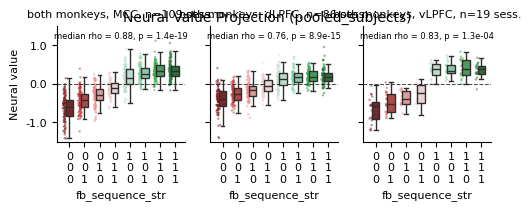

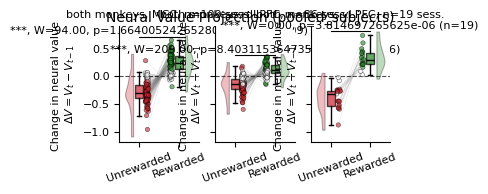

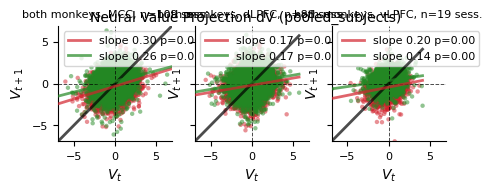

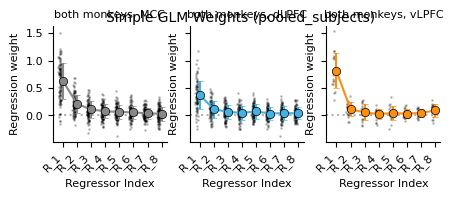

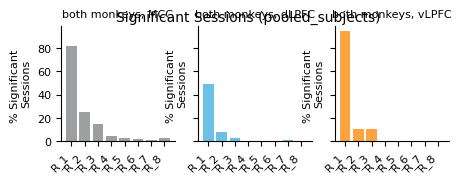

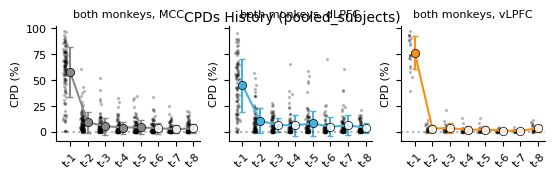

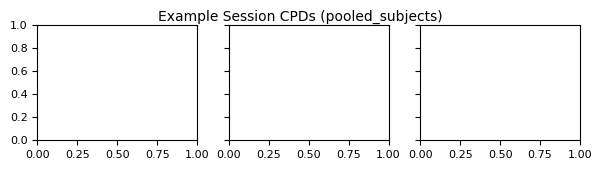

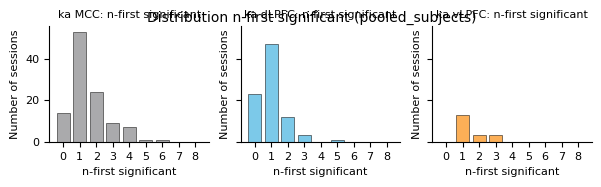

In [9]:
# Fig. 4: both monkeys pooled
run_short_history_analysis(short_history_data, monkeys_mode='both', paper_format=paper_format)

In [10]:
# Export source data (Figure 4c)
from popy.source_data import export_source_data
from matplotlib.cbook import boxplot_stats  # the statistics drawn by the box plots

areas_sd = ['MCC', 'dLPFC', 'vLPFC']
sess_avg_sd = short_history_data['sess_avg_sequence']  # session means plotted above (dots and box plots)
dots_4c, boxes_4c, rhos_4c, rho_summary_4c = [], [], [], []
for area_sd in areas_sd:
    data_sd = sess_avg_sd[sess_avg_sd['subregion'] == area_sd]
    code_sd = data_sd['fb_sequence'].astype(int)  # 4 x outcome(t-1) + 2 x outcome(t-2) + outcome(t-3), 1: rewarded
    dots_4c.append(pd.DataFrame({
        'Monkey': data_sd['monkey'].str.upper(),
        'Session': data_sd['session'],
        'Area': area_sd,
        'Outcome history code (x position, 0-7)': code_sd,
        'Outcome t-1 (1: rewarded)': code_sd // 4,
        'Outcome t-2 (1: rewarded)': (code_sd // 2) % 2,
        'Outcome t-3 (1: rewarded)': code_sd % 2,
        'Neural value (session mean, z-score)': data_sd['V_t'],
    }))
    for code_i_sd in sorted(code_sd.unique()):
        values_sd = data_sd.loc[code_sd == code_i_sd, 'V_t'].values
        box_sd = boxplot_stats(values_sd, whis=1.5)[0]
        boxes_4c.append({'Area': area_sd, 'Outcome history code (x position, 0-7)': code_i_sd,
                         'Outcomes (t-1, t-2, t-3)': f'({code_i_sd // 4}, {(code_i_sd // 2) % 2}, {code_i_sd % 2})', 'n sessions': len(values_sd),
                         'Median (z-score)': box_sd['med'], 'Q1 (z-score)': box_sd['q1'], 'Q3 (z-score)': box_sd['q3'],
                         'Lower whisker (z-score)': box_sd['whislo'], 'Upper whisker (z-score)': box_sd['whishi']})
    # rho: within-session Spearman correlation between outcome history code and neural value, as in plot_Vt_per_sequence()
    rhos_sd = []
    for (monkey_sd, session_sd), sess_sd in data_sd.groupby(['monkey', 'session']):
        if sess_sd['fb_sequence'].nunique() >= 3:
            rho_sd = stats.spearmanr(sess_sd['fb_sequence'], sess_sd['V_t'])[0]
            rhos_sd.append(rho_sd)
            rhos_4c.append({'Monkey': monkey_sd.upper(), 'Session': session_sd, 'Area': area_sd, 'Spearman rho': rho_sd})
    rhos_sd = np.array(rhos_sd)
    rhos_sd = rhos_sd[~np.isnan(rhos_sd)]
    W_sd, p_sd, _, _ = wilcoxon_signed_rank(rhos_sd)
    rho_summary_4c.append({'Area': area_sd, 'n sessions': len(rhos_sd), 'Median rho': np.median(rhos_sd),
                           'Wilcoxon W': W_sd, 'p (two-sided Wilcoxon signed-rank test of the rhos vs. 0)': p_sd})

dots_4c = pd.concat(dots_4c, ignore_index=True)
n_sessions_sd = ', '.join(f'{a}: n = {n}' for a, n in dots_4c.groupby('Area', sort=False)['Session'].nunique().items())
ylim_sd = 1.5  # y-axis range of the plot: -1.5 to 1.5 (vt_ylim in run_short_history_analysis)
n_out_sd = dots_4c.loc[dots_4c['Neural value (session mean, z-score)'].abs() > ylim_sd].groupby('Area', sort=False).size()
out_text_sd = ''.join(f' {n} {a} dot(s) outside the y-axis range (-{ylim_sd} to {ylim_sd}) not visible.' for a, n in n_out_sd.items())
export_source_data(
    'Figure 4c',
    {'Dots: session means': dots_4c,
     'Box plots (of the session means)': pd.DataFrame(boxes_4c),
     'Within-session Spearman correlations': pd.DataFrame(rhos_4c),
     'rho (median of the within-session correlations) and test': pd.DataFrame(rho_summary_4c)},
    'Neural value (projection of the population activity onto the decision vector subspace of the feedback decoder, averaged over '
    f'the task engagement period, {time_interval[0]}-{time_interval[1]} s of the time-normalized trial, z-scored within session) as a '
    'function of the outcomes of the '
    f'last three trials (t-1, t-2, t-3; x position: history code = 4 x outcome(t-1) + 2 x outcome(t-2) + outcome(t-3), 1: rewarded), '
    f'both monkeys pooled ({n_sessions_sd} sessions). Dots: session means (one per session and outcome '
    'history; the horizontal jitter is random and not exported). Box plots: median, quartiles (Q1, Q3) and whiskers (most extreme values '
    'within 1.5 x IQR of the quartiles), outliers not drawn separately. rho: median of the within-session Spearman correlations between '
    'outcome history code (0-7) and session-mean neural value, tested against 0 with a two-sided Wilcoxon signed-rank test.' + out_text_sd)

Figure 4c: source data saved (1712 rows, 24 rows, 214 rows, 3 rows)


In [11]:
# Export source data (Figure 4d)
from popy.source_data import export_source_data
from joblib import Parallel, delayed
from statsmodels.stats.multitest import multipletests

# MCC and dLPFC (shown in the paper), same data and computation as in plot_cpds_history_neural_value()
sessions_4d, summary_4d = [], []
for area_sd in ['MCC', 'dLPFC']:
    cpd_sd = short_history_data['cpd'][short_history_data['cpd']['subregion'] == area_sd]
    cpd_cols_sd = [col for col in cpd_sd.columns if col.startswith('cpd_R_')]
    assert cpd_cols_sd == [f'cpd_R_{i}' for i in range(1, 9)]
    table_sd = pd.DataFrame({'Monkey': cpd_sd['monkey'].str.upper(), 'Session': cpd_sd['session'], 'Area': area_sd})
    for i in range(1, 9):
        table_sd[f'CPD t-{i} (%)'] = cpd_sd[f'cpd_R_{i}']
    sessions_4d.append(table_sd)

    means_sd, sds_sd = cpd_sd[cpd_cols_sd].mean().values, cpd_sd[cpd_cols_sd].std().values
    # filled circles: one-sided permutation test of the mean CPD against the null of create_permutation_null() (CPD of a
    # shuffled regressor, n_perms permutations), FDR-corrected across lags, as in the plot. The null is random and is generated
    # again here (in 10 parallel chunks of n_perms / 10 permutations), so the p-values can differ slightly from the printed ones.
    behav_sd = short_history_data['behav'][short_history_data['behav']['subregion'] == area_sd]
    null_chunks_sd = Parallel(n_jobs=10)(delayed(create_permutation_null)(behav_sd, n_perms=n_perms // 10) for _ in range(10))
    null_sd = np.concatenate(null_chunks_sd)
    _, pvals_fdr_sd, _, _ = multipletests([np.sum(null_sd >= m) / null_sd.shape[0] for m in means_sd], method='fdr_bh')
    for i in range(8):
        summary_4d.append({'Area': area_sd, 'Trial in past': f't-{i + 1}', 'n sessions': len(cpd_sd),
                           'Mean CPD (circle, %)': means_sd[i], 'S.d. CPD (error bar, %)': sds_sd[i],
                           'Significant (filled circle; permutation test, FDR-corrected p < 0.05)': bool(pvals_fdr_sd[i] < 0.05)})

sessions_4d = pd.concat(sessions_4d, ignore_index=True)
summary_4d = pd.DataFrame(summary_4d)
n_sessions_sd = ', '.join(f'{a}: n = {n}' for a, n in sessions_4d.groupby('Area', sort=False).size().items())
export_source_data(
    'Figure 4d',
    {'Grey dots: individual sessions': sessions_4d, 'Circles and error bars: mean and s.d. across sessions': summary_4d},
    'Coefficient of partial determination (CPD = (R2 full - R2 without the outcome) / R2 full x 100, %) of the outcomes of the past '
    'eight trials (t-1 to t-8) in a linear regression of the neural value (task engagement period, z-scored within session) on these '
    'outcomes, per session, in MCC and dLPFC (both monkeys '
    f'pooled; {n_sessions_sd} sessions). Grey dots: individual sessions (the horizontal jitter is random and not exported); circles '
    'and error bars: mean +/- s.d. across sessions; filled circles: significant lags (one-sided permutation test of the mean CPD against '
    f'the mean CPD of a shuffled regressor, {n_perms} permutations, Benjamini-Hochberg FDR-corrected across lags, p < 0.05).')

Figure 4d: source data saved (195 rows, 16 rows)


In [12]:
# Export source data (Figure 4e)
from popy.source_data import export_source_data
from matplotlib.cbook import boxplot_stats  # the statistics drawn by ax.boxplot

# session means plotted above (dots, box plots, half violins), and the paired test of create_r_style_plot()
outcomes_sd = {0: 'unrewarded', 1: 'rewarded'}
sessions_4e, boxes_4e, tests_4e = [], [], []
for area_sd in areas_sd:
    data_sd = short_history_data['sess_avg_fb'][short_history_data['sess_avg_fb']['subregion'] == area_sd]
    paired_sd = data_sd.pivot_table(index=['monkey', 'session'], columns='feedback', values='dV')  # one row per session
    signif_sd = data_sd.groupby(['monkey', 'session'])['signif'].first().loc[paired_sd.index]
    sessions_4e.append(pd.DataFrame({
        'Monkey': paired_sd.index.get_level_values('monkey').str.upper(),
        'Session': paired_sd.index.get_level_values('session'),
        'Area': area_sd,
        'Delta V_neural after unrewarded trial (arb. units)': paired_sd[0].values,
        'Delta V_neural after rewarded trial (arb. units)': paired_sd[1].values,
        'Significant within-session difference (filled dots; Mann-Whitney U test, p < 0.05)': signif_sd.values,
    }))
    for fb_sd, outcome_sd in outcomes_sd.items():
        values_sd = data_sd.loc[data_sd['feedback'] == fb_sd, 'dV'].values
        box_sd = boxplot_stats(values_sd)[0]
        boxes_4e.append({'Area': area_sd, 'Outcome of trial t': outcome_sd, 'n sessions': len(values_sd),
                         'Median (arb. units)': box_sd['med'], 'Q1 (arb. units)': box_sd['q1'], 'Q3 (arb. units)': box_sd['q3'],
                         'Lower whisker (arb. units)': box_sd['whislo'], 'Upper whisker (arb. units)': box_sd['whishi']})
    diffs_sd = (paired_sd[1] - paired_sd[0]).dropna()
    W_sd, p_sd, _, _ = wilcoxon_signed_rank(diffs_sd.values)
    tests_4e.append({'Area': area_sd, 'n sessions': len(diffs_sd), 'Median difference rewarded - unrewarded (arb. units)': np.median(diffs_sd),
                     'Wilcoxon W': W_sd, 'p (two-sided Wilcoxon signed-rank test, paired by session)': p_sd})

sessions_4e = pd.concat(sessions_4e, ignore_index=True)
n_sessions_sd = ', '.join(f'{a}: n = {n}' for a, n in sessions_4e.groupby('Area', sort=False).size().items())
export_source_data(
    'Figure 4e',
    {'Connected dots: session means': sessions_4e, 'Box plots (of the session means)': pd.DataFrame(boxes_4e),
     'Rewarded vs. unrewarded (bracket)': pd.DataFrame(tests_4e)},
    'Trial-by-trial change in neural value (Delta V_neural = V(t+1) - V(t), neural value of the task engagement period z-scored within '
    'session, arbitrary units) after unrewarded and rewarded trials t, averaged per session (connected dots; the horizontal jitter is '
    f'random and not exported), both monkeys pooled ({n_sessions_sd} sessions). Filled dots: sessions with a significant within-session '
    'difference between rewarded and unrewarded trials (two-sided Mann-Whitney U test on single trials, p < 0.05). Box plots: median, '
    'quartiles (Q1, Q3) and whiskers (most extreme values within 1.5 x IQR of the quartiles), outliers not drawn separately; half '
    'violins: kernel density estimates of the same session means. Bracket: two-sided Wilcoxon signed-rank test, paired by session.')

Figure 4e: source data saved (214 rows, 6 rows, 3 rows)


---
# Fig. 4f, Example session

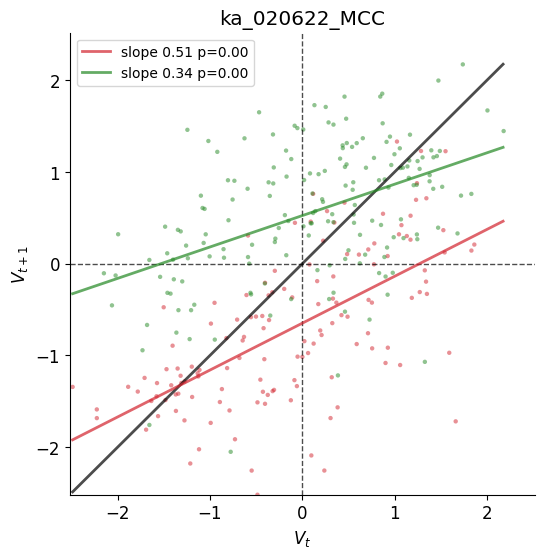

In [13]:
# example MCC session of Fig. 4f
monkey, session, subregion = 'ka', '020622', 'MCC'
behav_new = short_history_data['behav']
behav_new_temp = behav_new[(behav_new.monkey==monkey) & (behav_new.session==session) & (behav_new.subregion==subregion)]

green_red_plot(behav_new_temp, paper_format=False)
plt.title(f'{monkey}_{session}_{subregion}')
plt.savefig(os.path.join(FIGS_PATH, 'fig4f_example_session.svg'), dpi=300, bbox_inches='tight', transparent=True)
plt.show()

In [14]:
# Export source data (Figure 4f)
from popy.source_data import export_source_data

# trials of the example session plotted above, and the lines of green_red_plot(): least-squares fits (scipy.stats.linregress)
# per outcome, drawn over x from the minimum to the maximum of V(t) in steps of 0.01, and the identity line
outcomes_sd = {0: 'unrewarded', 1: 'rewarded'}
trials_4f = pd.DataFrame({
    'Trial t': behav_new_temp['trial_id'].values,
    'Outcome of trial t': behav_new_temp['feedback'].map(outcomes_sd).values,
    'Neural value in trial t (x, z-score)': behav_new_temp['V_t'].values,
    'Neural value in trial t+1 (y, z-score)': behav_new_temp['V_t_p1'].values,
})
x_lines_sd = np.arange(behav_new_temp['V_t'].min(), behav_new_temp['V_t'].max(), 0.01)
lines_4f = []
for fb_sd, outcome_sd in outcomes_sd.items():
    trials_sd = behav_new_temp[behav_new_temp['feedback'] == fb_sd]
    fit_sd = stats.linregress(trials_sd['V_t'].values, trials_sd['V_t_p1'].values)
    lines_4f.append({'Line': f'Linear fit, {outcome_sd} trials ({"green" if fb_sd else "red"})', 'n trials': len(trials_sd),
                     'Slope': fit_sd.slope, 'Intercept': fit_sd.intercept, 'Pearson r': fit_sd.rvalue, 'p (slope, two-sided)': fit_sd.pvalue,
                     'x from': x_lines_sd[0], 'x to': x_lines_sd[-1]})
lines_4f.append({'Line': 'Identity line y = x (black)', 'Slope': 1.0, 'Intercept': 0.0, 'x from': x_lines_sd[0], 'x to': x_lines_sd[-1]})

export_source_data(
    'Figure 4f',
    {f'Dots: trials of session {monkey.upper()} {session}, {subregion}': trials_4f, 'Lines': pd.DataFrame(lines_4f)},
    f'Example {subregion} session (monkey {monkey.upper()}, session {session}): neural value (task engagement period, z-scored within '
    f'session, arbitrary units) in trial t+1 vs. in trial t, one dot per trial t (n = {len(trials_4f)} trials), colored by the outcome of '
    'trial t (green: rewarded, red: unrewarded). Lines: least-squares linear regression of V(t+1) on V(t) for each outcome (y = slope x '
    '+ intercept, drawn for x between the given limits), and identity line (black). Dashed lines: 0.')

Figure 4f: source data saved (308 rows, 3 rows)


---
# Delta-rule consistent sessions (Results text)

GLM of $V(t+1)$ on $V(t)$, feedback and their interaction in each session; a session is delta-rule consistent if both slopes are within [0, 1] and the intercept is higher after rewarded trials.

In [15]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

alpha = 0.05  # significance level

# -----------------------------
# Pick time window & session
# -----------------------------
time_interval = (1.5, 3.5)  # time window for V_t and V_t+1
behav_new['V_t']    = behav_new[f'V_t_{time_interval[0]}_{time_interval[1]}']
behav_new['V_t_p1'] = behav_new[f'V_t_p1_{time_interval[0]}_{time_interval[1]}']

res = []  # if not yet defined

for (monkey, session, subregion), behav_new_temp in behav_new.groupby(['monkey', 'session', 'subregion']):

    # Extract datapoints (FILTERED)
    V_t = behav_new_temp['V_t'].values
    V_t1 = behav_new_temp['V_t_p1'].values
    fb_vector = behav_new_temp['feedback'].values

    # create a dataframe, column A is V_t1, B is V_t, C is fb_vector
    data_temp = pd.DataFrame({
        'A': V_t1,
        'B': V_t,
        'C': fb_vector
    })

    results_mixed = fit_mixed_glm(data_temp)
    test_results = stat_tests_mixed_glm(results_mixed)
    hypothesis = add_hypothesis(test_results)

    # -----------------------------
    # Package per-session results (trimmed)
    # -----------------------------
    session_result = {
        'monkey': monkey,
        'session': session,
        'subregion': subregion,

        # mean(Vt+1) comparison
        #'mean_vt1_pos': mean_vt1_pos,
        #'mean_vt1_neg': mean_vt1_neg,
        #'p_neg_mean_lt_pos': p_neg_mean_lt_pos,

        # regression summaries
        #'slope_all': slope_all,
        #'intercept_all': intercept_all,
        #'r2_all': np.nan if np.isnan(r_all) else r_all**2,
        #'p_model_all': p_all,          # slope 2-sided p in simple LR

        'slope_pos': test_results['slope_c1'],
        'intercept_pos': test_results['intercept_c1'],
        #'r2_pos': np.nan if np.isnan(r_pos) else r_pos**2,
        'slope_pos_nonzero': test_results['b1_c1_significant'],          # slope 2-sided p in simple LR
        'slope_pos_withinbounds': test_results['b1_c1_within_bounds'],          # slope 2-sided p in simple LR

        'slope_neg': test_results['slope_c0'],
        'intercept_neg': test_results['intercept_c0'],
        #'r2_neg': np.nan if np.isnan(r_neg) else r_neg**2,
        'slope_neg_nonzero': test_results['b1_c0_significant'],          # slope 2-sided p in simple LR
        'slope_neg_withinbounds': test_results['b1_c0_within_bounds'],          # slope 2-sided p in simple LR

        # intercept higher
        'intercept_pos_higher': test_results['intercept_c1_higher'],

        # Add hypothesis
        'hypothesis': hypothesis,

        # one-tailed tests for slope constraints
        #'p_pos_gt0': p_pos_gt0,
        #'p_pos_lt1': p_pos_lt1,
        #'p_neg_gt0': p_neg_gt0,
        #'p_neg_lt1': p_neg_lt1,
    }

    res.append(session_result)

res_df = pd.DataFrame(res)
res_df

,monkey,session,subregion,slope_pos,intercept_pos,slope_pos_nonzero,slope_pos_withinbounds,slope_neg,intercept_neg,slope_neg_nonzero,slope_neg_withinbounds,intercept_pos_higher,hypothesis
0,ka,010720,MCC,0.381777,0.409542,True,True,0.468393,-0.435312,True,True,True,Delta rule (strict)
1,ka,010720,vLPFC,0.221830,0.162352,True,True,0.132338,-0.195063,False,False,True,Delta rule (loose)
2,ka,010822,MCC,0.125676,0.182373,False,False,0.020985,-0.266862,False,False,True,Feedback
3,ka,010822,dLPFC,-0.036710,0.108383,False,False,-0.057459,-0.156559,False,False,True,Feedback
4,ka,010922,MCC,-0.281018,-0.000861,True,False,0.104301,0.084863,False,False,False,Other
...,...,...,...,...,...,...,...,...,...,...,...,...,...
209,po,300322,vLPFC,0.142118,0.146257,True,True,0.176821,-0.137341,True,True,True,Delta rule (strict)
210,po,300421,MCC,0.322608,0.312150,True,True,0.273197,-0.350941,True,True,True,Delta rule (strict)
211,po,300421,dLPFC,0.102604,0.123857,False,False,0.111325,-0.135177,False,False,True,Feedback
212,po,310822,MCC,0.616231,0.083035,True,True,0.688054,-0.071550,True,True,True,Delta rule (strict)


In [16]:
# Print delta statistics in the requested format
total_sessions = len(res_df)
delta_sessions = len(res_df[res_df['hypothesis'] == 'Delta rule (strict)'])
delta_pct = (delta_sessions / total_sessions) * 100

# Build statistics string in exact format requested
stats_parts = []
for monkey in ['ka', 'po']:
    monkey_data = res_df[res_df['monkey'] == monkey]
    for area in res_df['subregion'].unique():
        area_data = monkey_data[monkey_data['subregion'] == area]
        total_area = len(area_data)
        if total_area > 0:
            delta_count = len(area_data[area_data['hypothesis'] == 'Delta rule (strict)'])
            pct = (delta_count / total_area) * 100
            stats_parts.append(f"{monkey.upper()} – {area}: {delta_count}/{total_area}, {pct:.1f}%")

print(f"Under p < 0.05, {delta_pct:.1f}% of all sessions ({delta_sessions} of all {total_sessions}) passed all three criteria ({'; '.join(stats_parts)})")

Under p < 0.05, 45.8% of all sessions (98 of all 214) passed all three criteria (KA – MCC: 41/58, 70.7%; KA – vLPFC: 2/12, 16.7%; KA – dLPFC: 10/46, 21.7%; PO – MCC: 28/51, 54.9%; PO – vLPFC: 3/7, 42.9%; PO – dLPFC: 14/40, 35.0%)
